  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
--- 5 dòng đầu tiên ---
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 

C:\Users\WIN\AppData\Local\Temp\ipykernel_13008\3616816351.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=wine_data, x='quality', palette='viridis')


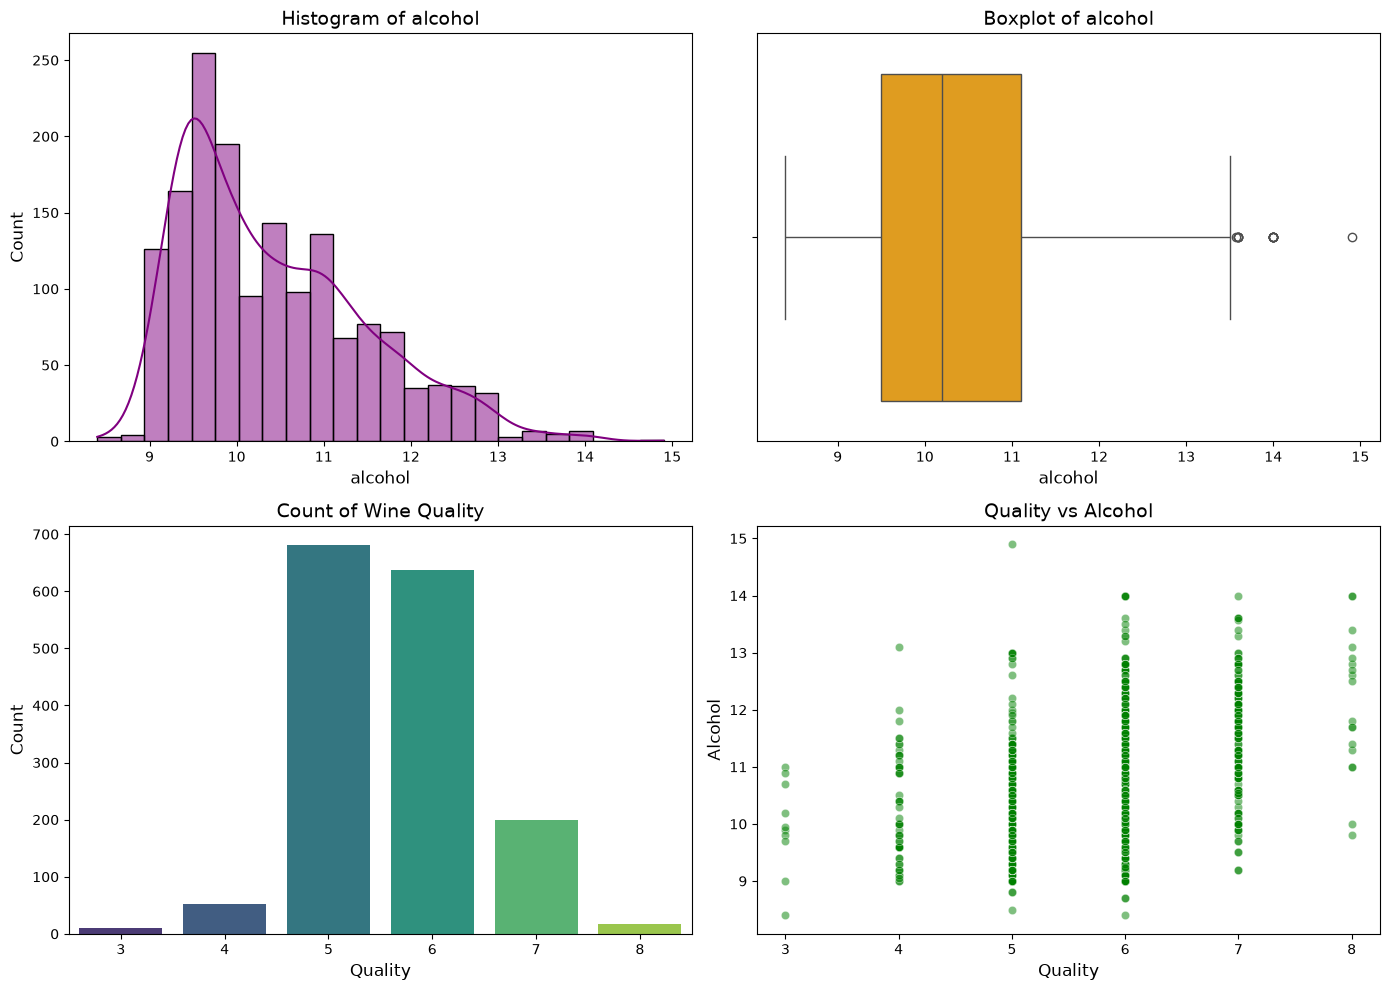

In [8]:
!pip install seaborn matplotlib pandas numpy scipy

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Nạp tập dữ liệu rượu đỏ vào DataFrame (thay đổi tên file .csv cho khớp với file bạn đã tải)
wine_data = pd.read_csv("winequality-red.csv")

# Kiểm tra sơ bộ dữ liệu
print("--- 5 dòng đầu tiên ---")
print(wine_data.head(5))
print("\n--- Kiểu dữ liệu ---")
print(wine_data.dtypes)
print("\n--- Kích thước dữ liệu ---")
print(wine_data.shape)

# Chọn cột muốn phân tích (ví dụ: 'alcohol' hoặc 'quality')
target_col = "alcohol"

# 2. Tính toán các chỉ số thống kê mô tả
data_mean = np.mean(wine_data[target_col])
data_median = np.median(wine_data[target_col])
data_mode = stats.mode(wine_data[target_col], keepdims=True)
data_variance = np.var(wine_data[target_col])
data_sd = np.std(wine_data[target_col])
data_max = np.max(wine_data[target_col])
data_min = np.min(wine_data[target_col])
data_percentile = np.percentile(wine_data[target_col], 60)
data_quartile = np.quantile(wine_data[target_col], 0.75)
data_IQR = stats.iqr(wine_data[target_col])

print(f"\n--- Thống kê mô tả cho cột '{target_col}' ---")
print(f"Mean: {data_mean:.2f}")
print(f"Median: {data_median:.2f}")
print(f"Standard Deviation: {data_sd:.2f}")
print(f"Min: {data_min} | Max: {data_max}")
print(f"IQR: {data_IQR:.2f}")

# 3. Trực quan hóa dữ liệu (Vẽ biểu đồ)
plt.figure(figsize=(14, 10))

# Biểu đồ 1: Histogram phân bố dữ liệu (Đơn biến)
plt.subplot(2, 2, 1)
sns.histplot(data=wine_data, x=target_col, kde=True, color='purple')
plt.title(f'Histogram of {target_col}', fontsize=14)
plt.xlabel(target_col, fontsize=12)
plt.ylabel('Count', fontsize=12)

# Biểu đồ 2: Boxplot để kiểm tra ngoại lai (Outliers)
plt.subplot(2, 2, 2)
sns.boxplot(data=wine_data, x=target_col, color='orange')
plt.title(f'Boxplot of {target_col}', fontsize=14)
plt.xlabel(target_col, fontsize=12)

# Biểu đồ 3: Bar chart đếm số lượng theo chất lượng rượu (quality)
plt.subplot(2, 2, 3)
sns.countplot(data=wine_data, x='quality', palette='viridis')
plt.title('Count of Wine Quality', fontsize=14)
plt.xlabel('Quality', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Biểu đồ 4: Scatter plot phân tích quan hệ giữa 'alcohol' và 'quality' (Hai biến)
plt.subplot(2, 2, 4)
sns.scatterplot(data=wine_data, x='quality', y='alcohol', alpha=0.5, color='green')
plt.title('Quality vs Alcohol', fontsize=14)
plt.xlabel('Quality', fontsize=12)
plt.ylabel('Alcohol', fontsize=12)

plt.tight_layout()
plt.show()